Kiểm tra ảnh trùng:   0%|          | 0/23708 [00:00<?, ?it/s]

Tổng số ảnh: 23708
Số ảnh thuộc nhóm mâu thuẫn: 419
Số ảnh trùng dư thừa: 176
Số ảnh còn lại: 23113


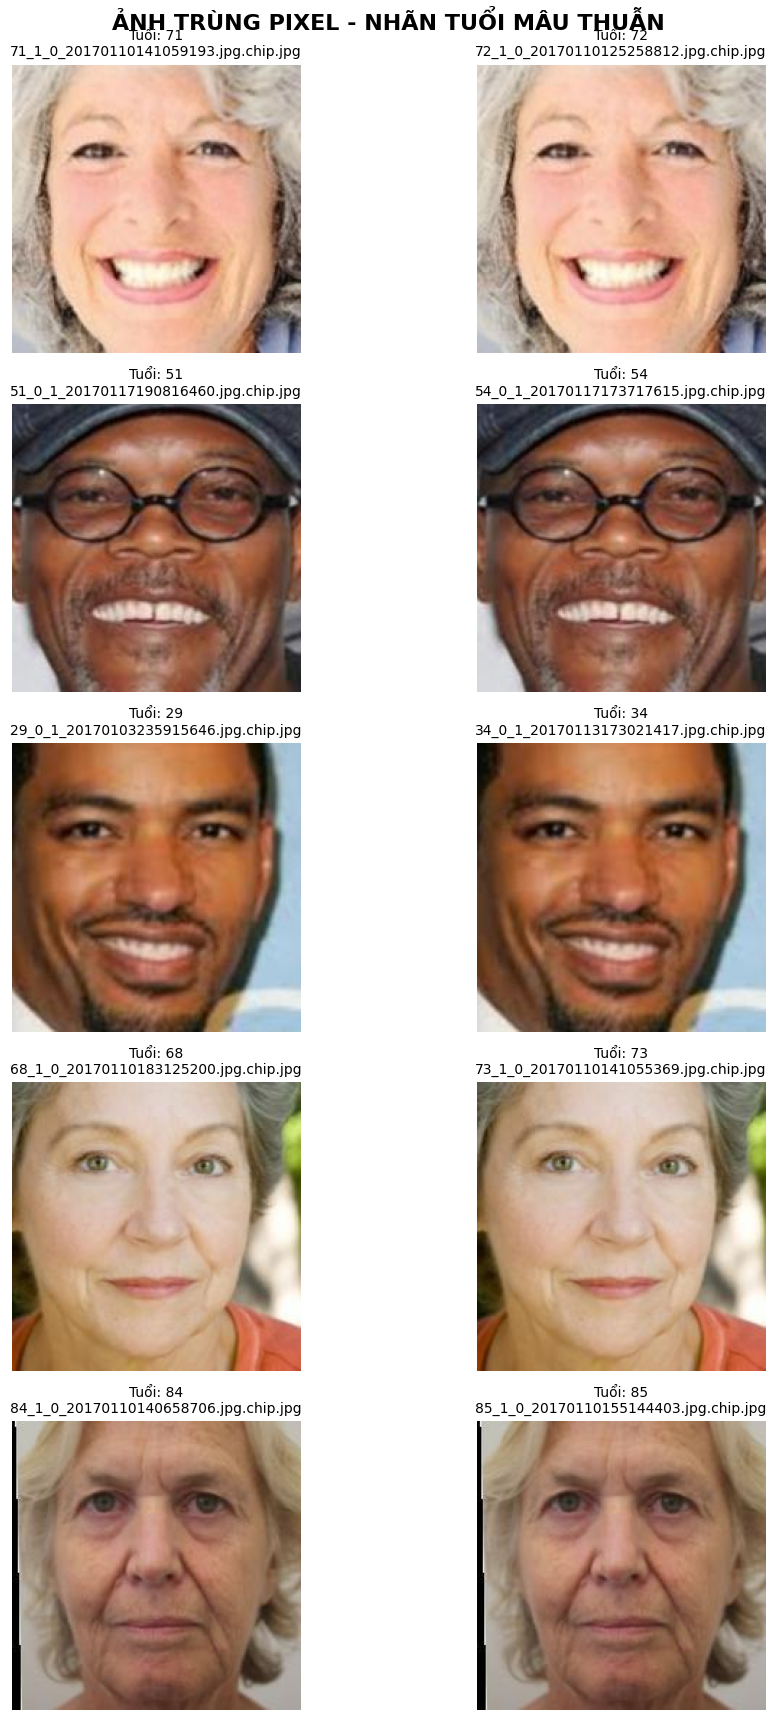

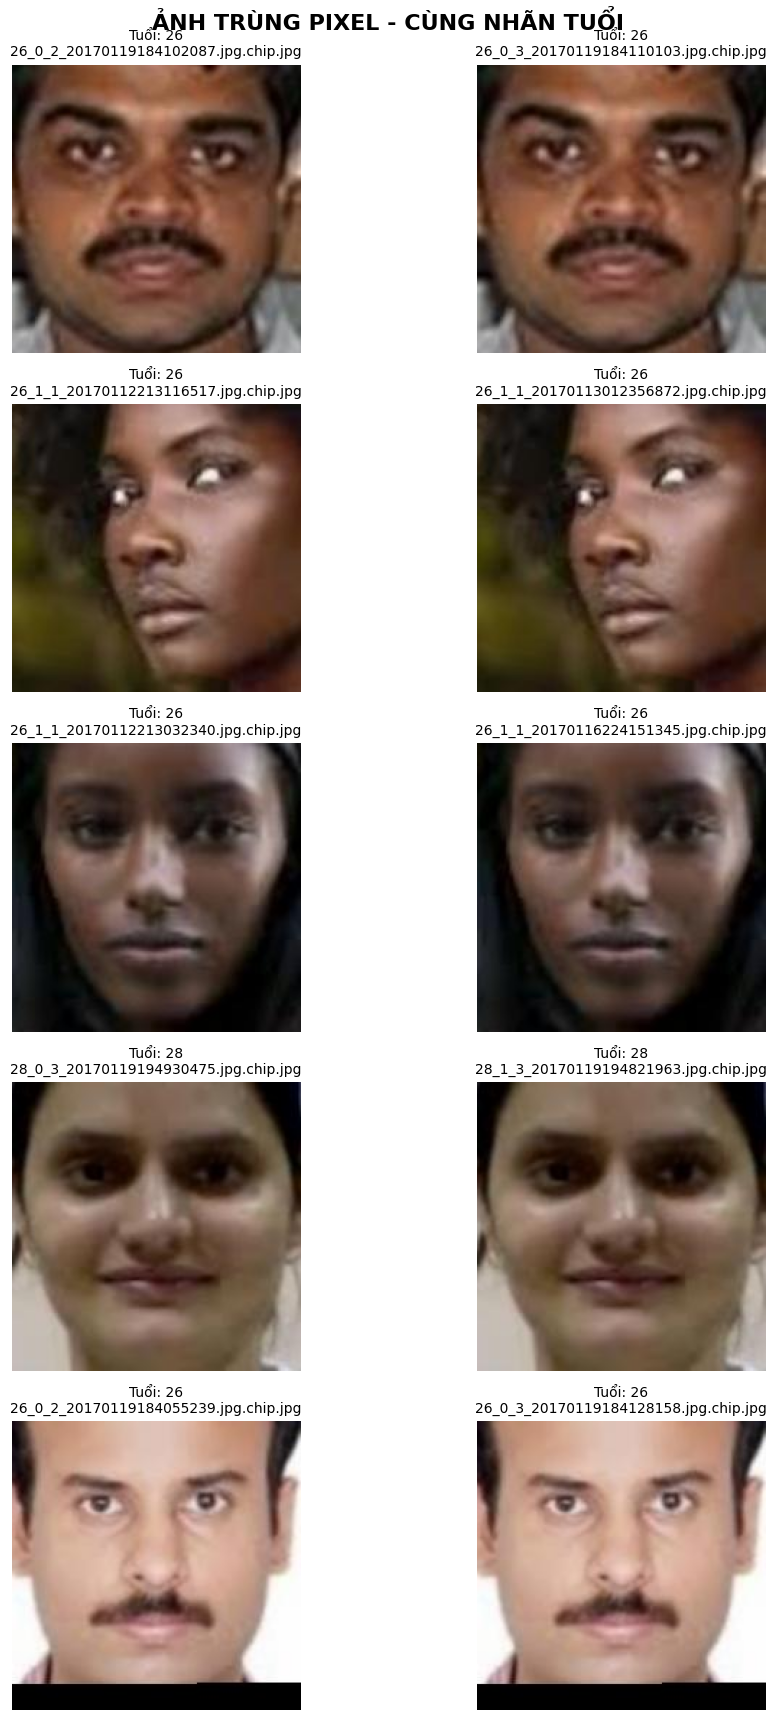

In [1]:

import os
import hashlib
import struct
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm

DATA_DIR = Path("/kaggle/input/datasets/jangedoo/utkface-new/UTKFace")

# 1. Tính SHA-256 từ pixel ảnh
def pixel_hash(path):
    with Image.open(path) as img:
        img = img.convert("RGB")
        content = struct.pack("<II", *img.size) + img.tobytes()
        return hashlib.sha256(content).hexdigest()

# 2. Đọc ảnh và nhãn tuổi từ tên file
rows = []
files = sorted(
    p for p in DATA_DIR.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

for path in tqdm(files, desc="Kiểm tra ảnh trùng"):
    try:
        age = int(path.name.split("_")[0])
        rows.append({
            "path": str(path),
            "filename": path.name,
            "age": age,
            "hash": pixel_hash(path)
        })
    except Exception:
        continue

df = pd.DataFrame(rows)

# 3. Phân loại nhóm trùng
conflicts = []
duplicates = []

for _, group in df.groupby("hash"):
    if len(group) < 2:
        continue

    if group["age"].nunique() > 1:
        conflicts.append(group)
    else:
        duplicates.append(group)

print("Tổng số ảnh:", len(df))
print("Số ảnh thuộc nhóm mâu thuẫn:",
      sum(len(g) for g in conflicts))
print("Số ảnh trùng dư thừa:",
      sum(len(g) - 1 for g in duplicates))
print("Số ảnh còn lại:",
      len(df) - sum(len(g) for g in conflicts)
              - sum(len(g) - 1 for g in duplicates))

# 4. Hàm hiển thị các cặp ảnh
def show_duplicates(groups, title, n=5, conflict=False):
    groups = sorted(groups, key=len, reverse=True)[:n]

    if not groups:
        print("Không tìm thấy nhóm ảnh:", title)
        return

    fig, axes = plt.subplots(
        len(groups), 2,
        figsize=(11, 3.5 * len(groups)),
        squeeze=False
    )

    for i, group in enumerate(groups):
        first = group.iloc[0]

        if conflict:
            second = group[group["age"] != first["age"]].iloc[0]
        else:
            second = group.iloc[1]

        for j, row in enumerate([first, second]):
            with Image.open(row["path"]) as img:
                axes[i, j].imshow(img.convert("RGB"))

            axes[i, j].set_title(
                f"Tuổi: {row['age']}\n{row['filename']}",
                fontsize=10
            )
            axes[i, j].axis("off")

    fig.suptitle(title, fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.show()

# 5. Hiển thị ảnh trùng nhưng tuổi mâu thuẫn
show_duplicates(
    conflicts,
    "ẢNH TRÙNG PIXEL - NHÃN TUỔI MÂU THUẪN",
    n=5,
    conflict=True
)

# 6. Hiển thị ảnh trùng cùng nhãn tuổi
show_duplicates(
    duplicates,
    "ẢNH TRÙNG PIXEL - CÙNG NHÃN TUỔI",
    n=5,
    conflict=False
)


Tổng số ảnh hợp lệ: 23,705
Tuổi thấp nhất: 1 | Cao nhất: 116
Tuổi trung bình: 33.3 | Trung vị: 29


,tuoi,gioi_tinh,chung_toc,nhom_tuoi
0,26,Nam,Châu Á,20–35
1,22,Nữ,Da đen,20–35
2,21,Nữ,Ấn Độ,20–35
3,28,Nam,Da trắng,20–35
4,17,Nữ,Khác,13–19
5,44,Nam,Ấn Độ,36–59
6,35,Nam,Châu Á,20–35
7,76,Nam,Da trắng,60+
8,36,Nữ,Da trắng,36–59
9,34,Nam,Ấn Độ,20–35


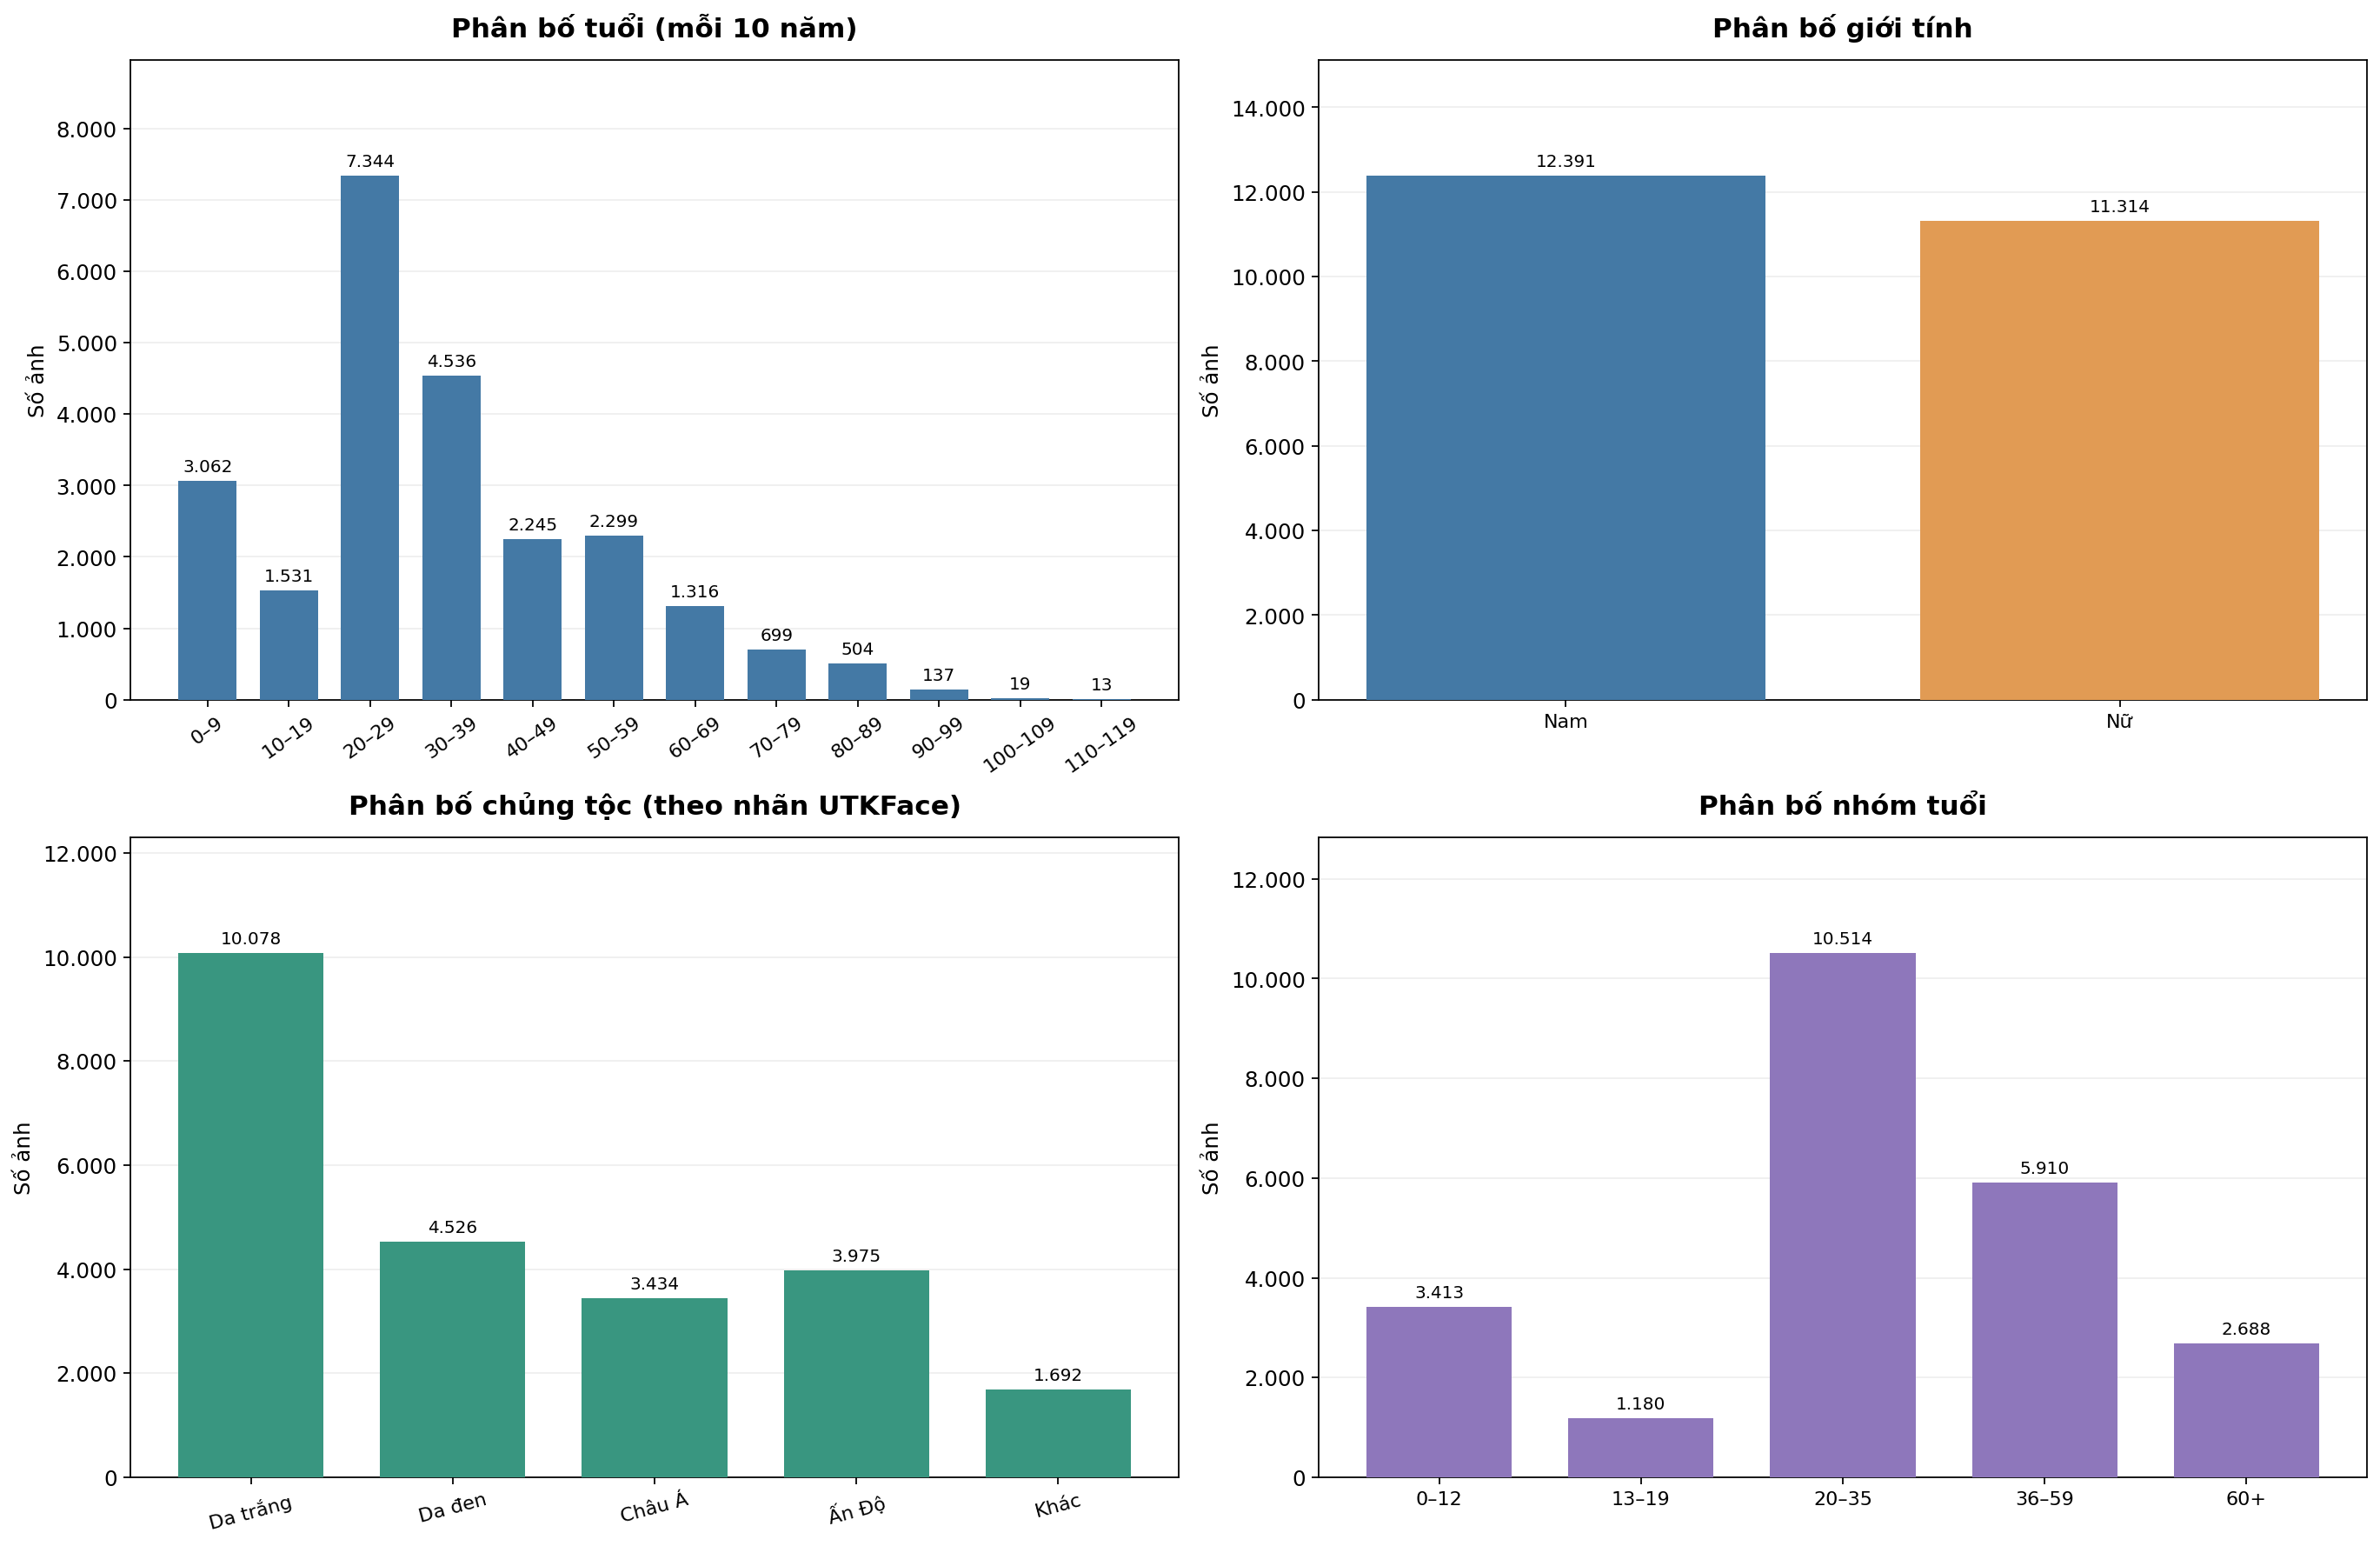


Giới tính


,Số ảnh,Tỷ lệ (%)
gioi_tinh,,
Nam,12391,52.27
Nữ,11314,47.73



Chủng tộc


,Số ảnh,Tỷ lệ (%)
chung_toc,,
Da trắng,10078,42.51
Da đen,4526,19.09
Châu Á,3434,14.49
Ấn Độ,3975,16.77
Khác,1692,7.14



Nhóm tuổi


,Số ảnh,Tỷ lệ (%)
nhom_tuoi,,
0–12,3413,14.40
13–19,1180,4.98
20–35,10514,44.35
36–59,5910,24.93
60+,2688,11.34


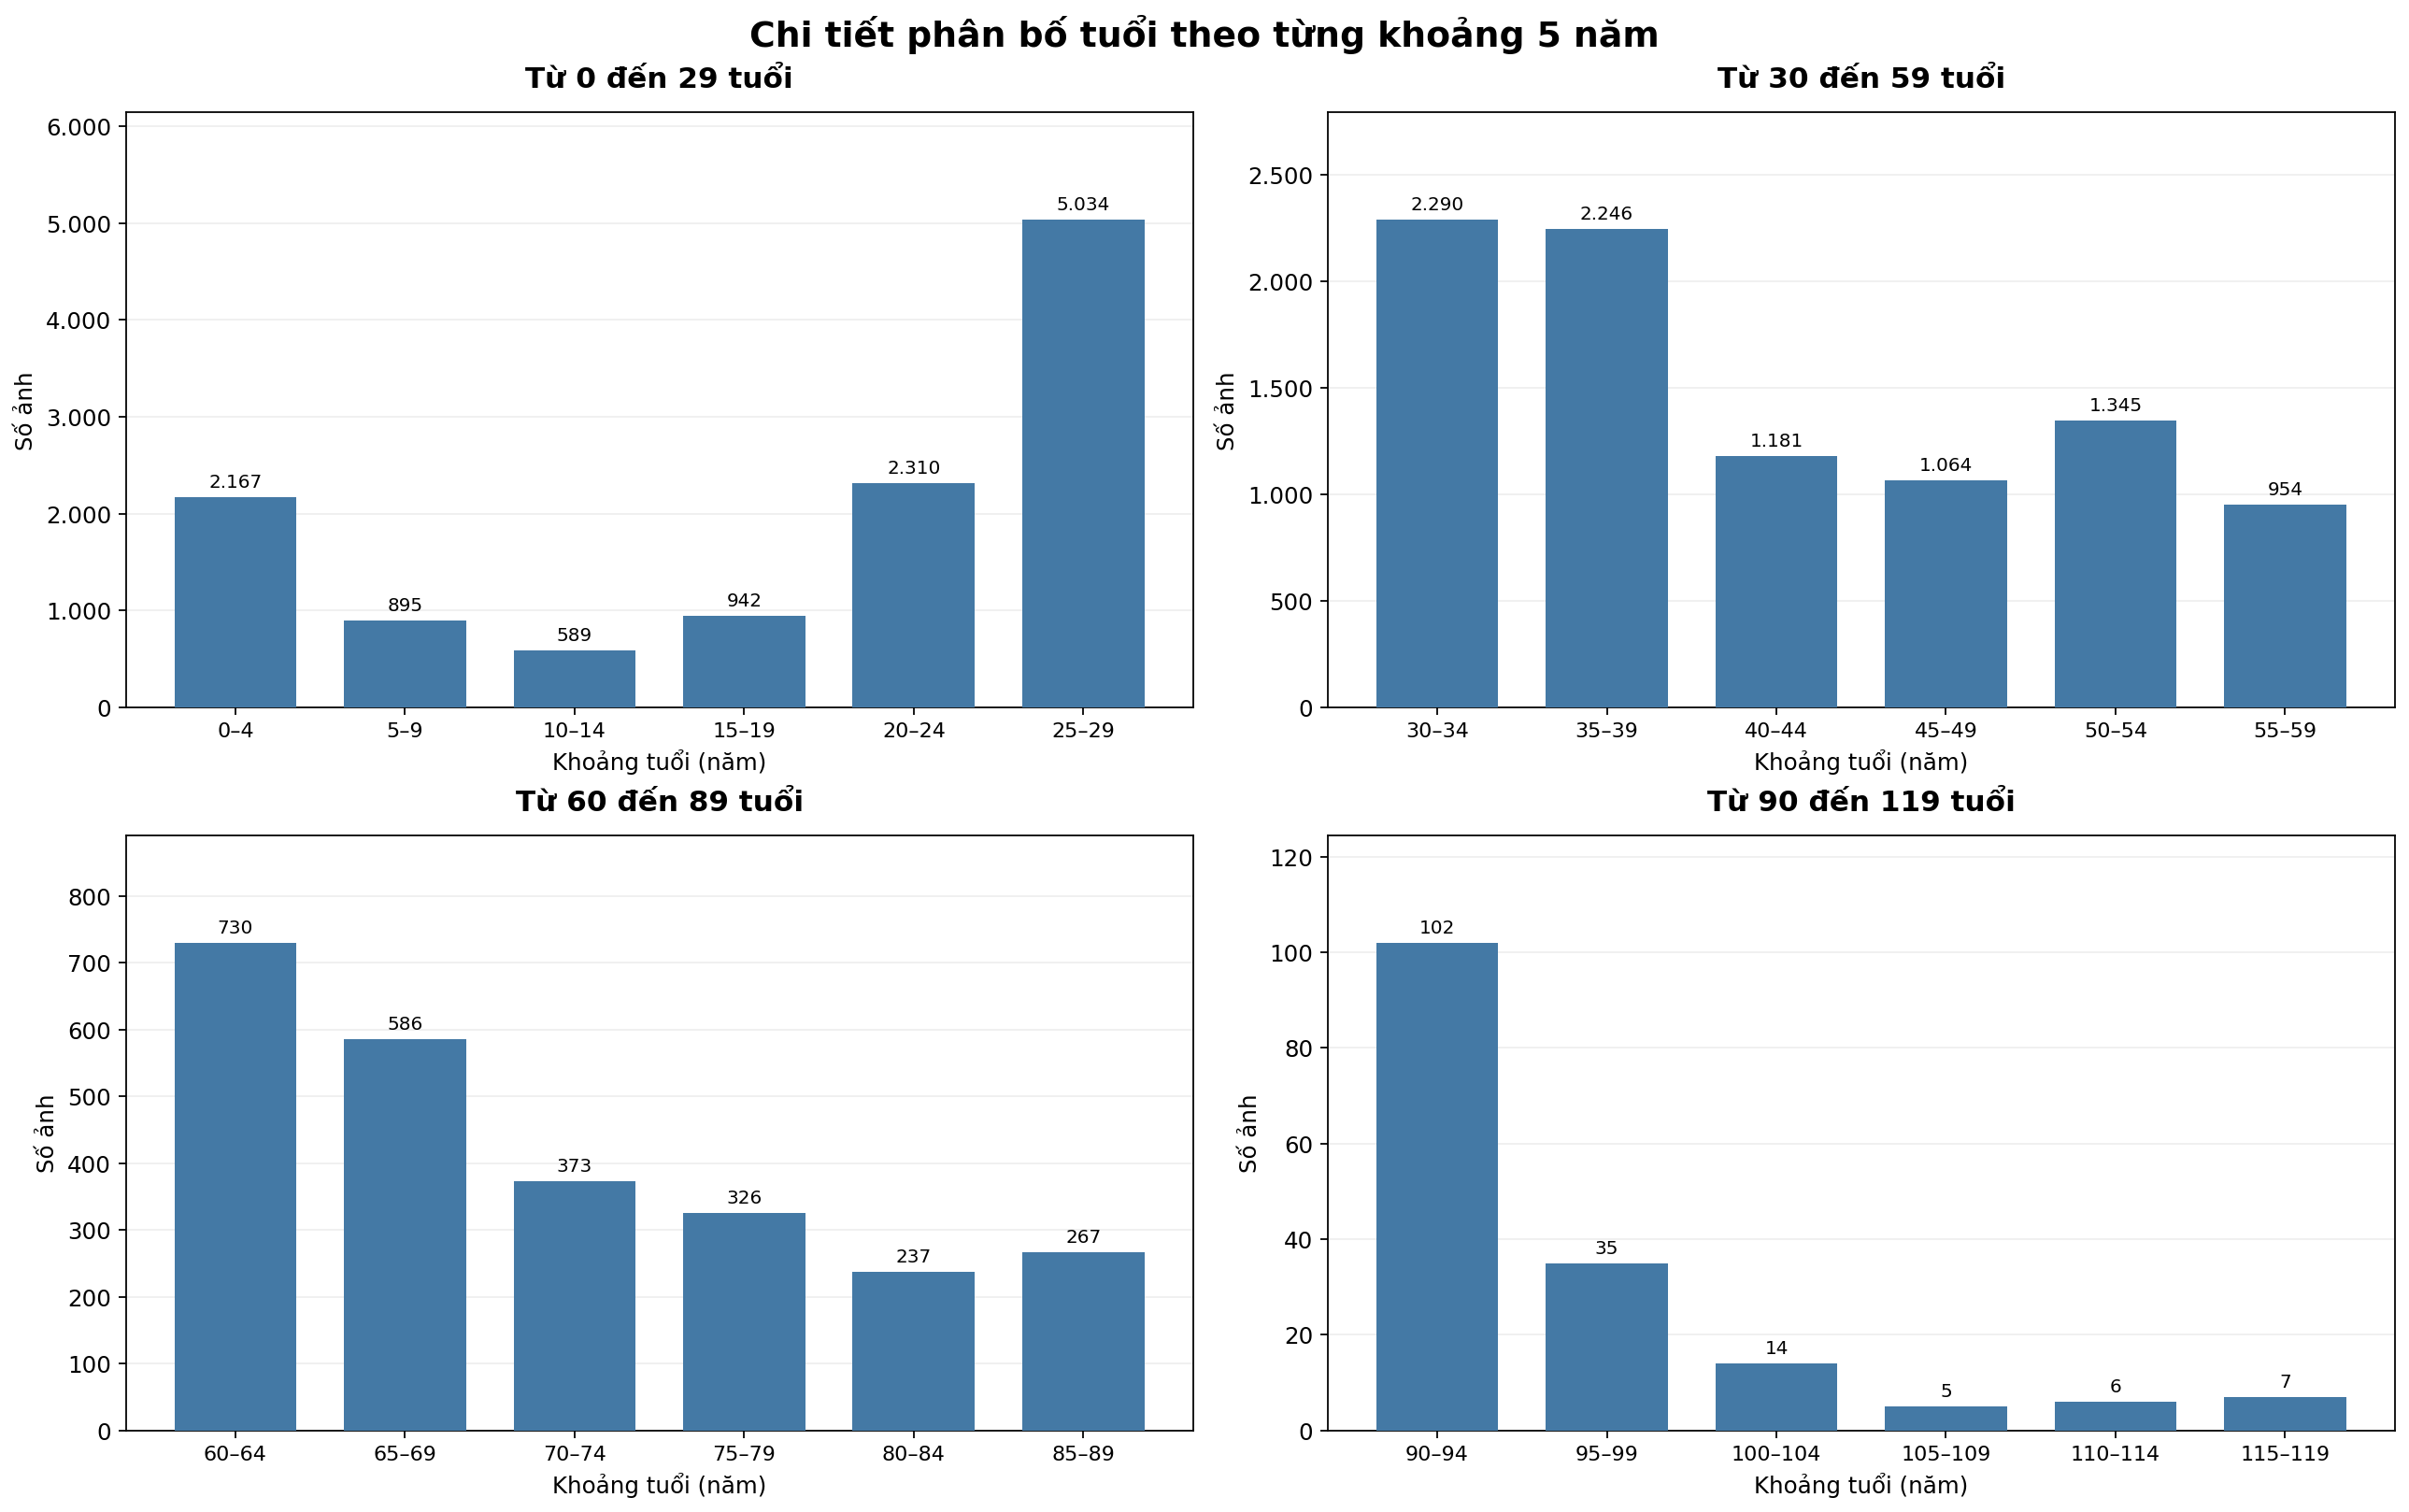

Lưu ý: mỗi biểu đồ sử dụng thang số ảnh khác nhau để nhìn rõ các nhóm ít mẫu.


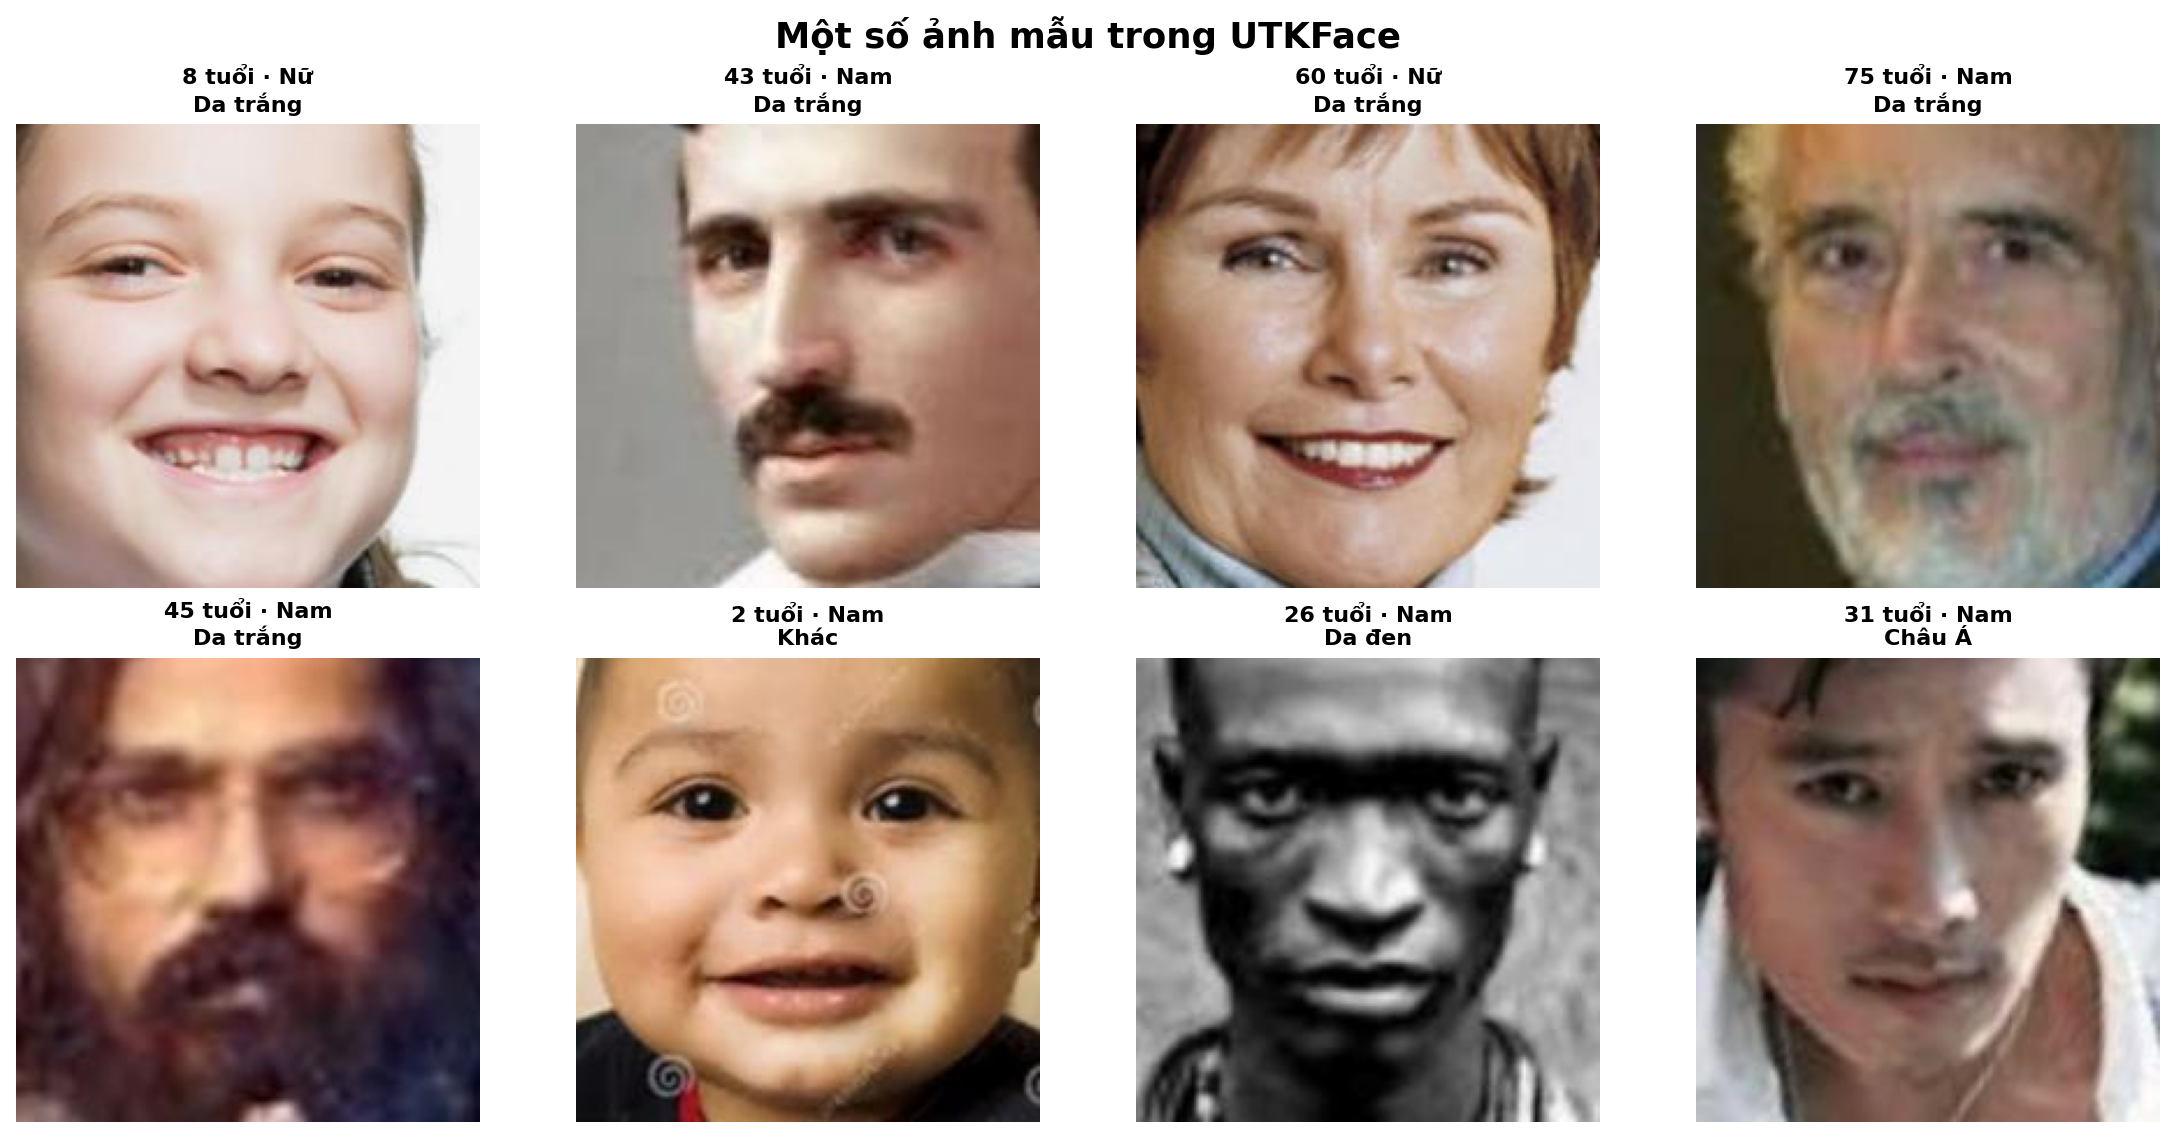

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from PIL import Image
from IPython.display import display

# Thay đường dẫn nếu dữ liệu nằm ở vị trí khác.
DATA_DIR = Path("/kaggle/input/datasets/jangedoo/utkface-new/UTKFace")
assert DATA_DIR.is_dir(), f"Không tìm thấy thư mục dữ liệu: {DATA_DIR}"

# Nhãn UTKFace nằm trong tên ảnh: tuổi_giới tính_chủng tộc_ngày.jpg
rows = []
for path in DATA_DIR.rglob("*.jpg"):
    parts = path.stem.split("_")
    if len(parts) < 4:
        continue
    try:
        tuoi, gioi_tinh, chung_toc = map(int, parts[:3])
    except ValueError:
        continue
    if 0 <= tuoi <= 116 and gioi_tinh in [0, 1] and chung_toc in range(5):
        rows.append([path, tuoi, gioi_tinh, chung_toc])

df = pd.DataFrame(rows, columns=["duong_dan", "tuoi", "ma_gioi_tinh", "ma_chung_toc"])
assert not df.empty, "Không tìm thấy ảnh hợp lệ. Hãy kiểm tra đường dẫn và tên tệp."

nhan_gioi_tinh = {0: "Nam", 1: "Nữ"}
nhan_chung_toc = {0: "Da trắng", 1: "Da đen", 2: "Châu Á", 3: "Ấn Độ", 4: "Khác"}
df["gioi_tinh"] = df["ma_gioi_tinh"].map(nhan_gioi_tinh)
df["chung_toc"] = df["ma_chung_toc"].map(nhan_chung_toc)
df["nhom_tuoi"] = pd.cut(
    df["tuoi"], bins=[-1, 12, 19, 35, 59, 116],
    labels=["0–12", "13–19", "20–35", "36–59", "60+"]
)

# Hiển thị sắc nét và hỗ trợ dấu tiếng Việt.
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "figure.dpi": 160,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

print(f"Tổng số ảnh hợp lệ: {len(df):,}")
print(f"Tuổi thấp nhất: {df['tuoi'].min()} | Cao nhất: {df['tuoi'].max()}")
print(f"Tuổi trung bình: {df['tuoi'].mean():.1f} | Trung vị: {df['tuoi'].median():.0f}")
display(df[["tuoi", "gioi_tinh", "chung_toc", "nhom_tuoi"]].head(10))

# ----------------------------------------------------------------------
# Biểu đồ tổng quan: tuổi (mỗi 10 năm), giới tính, chủng tộc, nhóm tuổi.
def ve_cot(ax, ten, so_luong, tieu_de, mau):
    cot = ax.bar(range(len(ten)), so_luong, color=mau, width=0.72, zorder=3)
    ax.set_xticks(range(len(ten)))
    ax.set_xticklabels(ten, fontsize=10)
    ax.set_title(tieu_de, pad=12)
    ax.set_ylabel("Số ảnh")
    ax.set_ylim(0, max(max(so_luong, default=0) * 1.22, 1))
    ax.grid(axis="y", alpha=0.20, zorder=0)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
    for thanh, so in zip(cot, so_luong):
        if so > 0:
            ax.annotate(f"{so:,}".replace(",", "."),
                        (thanh.get_x() + thanh.get_width() / 2, so),
                        xytext=(0, 3), textcoords="offset points",
                        ha="center", va="bottom", fontsize=9)

# Gom theo 10 tuổi để biểu đồ tổng quan không quá dày.
nhom_10 = pd.cut(df["tuoi"], bins=np.arange(0, 121, 10), right=False)
dem_tuoi_10 = nhom_10.value_counts().sort_index()
nhan_tuoi_10 = [f"{int(k.left)}–{int(k.right)-1}" for k in dem_tuoi_10.index]

dem_gioi_tinh = df["gioi_tinh"].value_counts().reindex(["Nam", "Nữ"], fill_value=0)
dem_chung_toc = df["chung_toc"].value_counts().reindex(list(nhan_chung_toc.values()), fill_value=0)
dem_nhom_tuoi = df["nhom_tuoi"].value_counts().sort_index()

fig, axs = plt.subplots(2, 2, figsize=(17, 11), layout="constrained")
ve_cot(axs[0, 0], nhan_tuoi_10, dem_tuoi_10.values, "Phân bố tuổi (mỗi 10 năm)", "#4479a5")
axs[0, 0].tick_params(axis="x", labelrotation=35)
ve_cot(axs[0, 1], dem_gioi_tinh.index.tolist(), dem_gioi_tinh.values, "Phân bố giới tính", ["#4479a5", "#e19b54"])
ve_cot(axs[1, 0], dem_chung_toc.index.tolist(), dem_chung_toc.values, "Phân bố chủng tộc (theo nhãn UTKFace)", "#399680")
ve_cot(axs[1, 1], dem_nhom_tuoi.index.astype(str).tolist(), dem_nhom_tuoi.values, "Phân bố nhóm tuổi", "#8e77bb")
axs[1, 0].tick_params(axis="x", labelrotation=15)
plt.show()

# Bảng số lượng và tỷ lệ hiển thị ngay bên dưới.
for tieu_de, thong_ke in [("Giới tính", dem_gioi_tinh), ("Chủng tộc", dem_chung_toc), ("Nhóm tuổi", dem_nhom_tuoi)]:
    print(f"\n{tieu_de}")
    display(pd.DataFrame({"Số ảnh": thong_ke, "Tỷ lệ (%)": (thong_ke / len(df) * 100).round(2)}))

# ----------------------------------------------------------------------
# PHÓNG TO PHÂN BỐ TUỔI: mỗi ô dùng trục số lượng riêng.
# Cách này giúp các nhóm tuổi ít ảnh không bị nén sát trục ngang.
ranh_gioi = [(0, 29), (30, 59), (60, 89), (90, 119)]
bins_5 = np.arange(0, 121, 5)
dem_5 = pd.cut(df["tuoi"], bins=bins_5, right=False).value_counts().sort_index()

fig, axs = plt.subplots(2, 2, figsize=(16, 10), layout="constrained")
for ax, (bat_dau, ket_thuc) in zip(axs.flat, ranh_gioi):
    chon = [k for k in dem_5.index if k.left >= bat_dau and k.left <= ket_thuc]
    gia_tri = dem_5.loc[chon].to_numpy()
    ten_cot = [f"{int(k.left)}–{int(k.right)-1}" for k in chon]
    ve_cot(ax, ten_cot, gia_tri, f"Từ {bat_dau} đến {ket_thuc} tuổi", "#4479a5")
    ax.set_xlabel("Khoảng tuổi (năm)")

fig.suptitle("Chi tiết phân bố tuổi theo từng khoảng 5 năm", fontsize=17, weight="bold")
plt.show()
print("Lưu ý: mỗi biểu đồ sử dụng thang số ảnh khác nhau để nhìn rõ các nhóm ít mẫu.")

anh_mau = df.sample(n=min(8, len(df)), random_state=2026)
fig, axs = plt.subplots(2, 4, figsize=(14, 7), layout="constrained")
for ax in axs.flat:
    ax.axis("off")
for ax, (_, hang) in zip(axs.flat, anh_mau.iterrows()):
    with Image.open(hang["duong_dan"]) as anh:
        ax.imshow(anh.convert("RGB"))
    ax.set_title(f"{hang['tuoi']} tuổi · {hang['gioi_tinh']}\n{hang['chung_toc']}", fontsize=10)
fig.suptitle("Một số ảnh mẫu trong UTKFace", fontsize=16, weight="bold")
plt.show()

